In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

print("Scikit-learn version:", sklearn.__version__)
print("All libraries imported successfully!")

Scikit-learn version: 1.8.0
All libraries imported successfully!


In [3]:
# Create a sample dataset
data = {
    "Study_Hours": [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
        1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5
    ],
    "Marks": [
        35, 40, 50, 55, 65, 70, 75, 85, 90, 95,
        38, 45, 52, 60, 67, 72, 80, 87, 92, 98
    ]
}

# Convert the data into a DataFrame
df = pd.DataFrame(data)

# Display the dataset
print("Student Marks Dataset:")
display(df)

# Display dataset information
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Student Marks Dataset:


,Study_Hours,Marks
0,1.0,35
1,2.0,40
2,3.0,50
3,4.0,55
4,5.0,65
5,6.0,70
6,7.0,75
7,8.0,85
8,9.0,90
9,10.0,95


Dataset Shape: (20, 2)
Number of Rows: 20
Number of Columns: 2


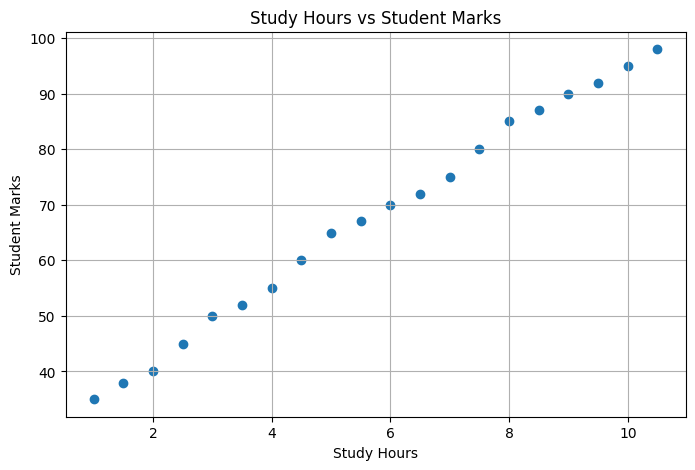

In [4]:
# Visualize the relationship between study hours and marks

plt.figure(figsize=(8, 5))

plt.scatter(df["Study_Hours"], df["Marks"])

plt.xlabel("Study Hours")
plt.ylabel("Student Marks")
plt.title("Study Hours vs Student Marks")

plt.grid(True)
plt.show()

In [5]:
# Separate input features and target variable

X = df[["Study_Hours"]]
y = df["Marks"]

print("Input Feature (X):")
display(X.head())

print("Target Variable (y):")
display(y.head())

Input Feature (X):


,Study_Hours
0,1.0
1,2.0
2,3.0
3,4.0
4,5.0


Target Variable (y):


0    35
1    40
2    50
3    55
4    65
Name: Marks, dtype: int64

In [6]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Total records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining Features:")
display(X_train)

print("Testing Features:")
display(X_test)

Total records: 20
Training records: 16
Testing records: 4

Training Features:


,Study_Hours
8,9.0
5,6.0
11,2.5
3,4.0
18,9.5
16,7.5
13,4.5
2,3.0
9,10.0
19,10.5


Testing Features:


,Study_Hours
0,1.0
17,8.5
15,6.5
1,2.0


In [7]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

# Display the learned parameters
print("Linear Regression model trained successfully!")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Linear Regression model trained successfully!
Slope: 6.680041688379364
Intercept: 29.3147472642001


In [8]:
# Predict marks using the testing data
y_pred = model.predict(X_test)

print("Predicted Marks:")
print(y_pred)

print("\nActual Marks:")
print(y_test.values)

Predicted Marks:
[35.99478895 86.09510162 72.73501824 42.67483064]

Actual Marks:
[35 87 72 40]


In [9]:
# Compare actual and predicted marks
results = pd.DataFrame({
    "Study_Hours": X_test["Study_Hours"].values,
    "Actual_Marks": y_test.values,
    "Predicted_Marks": np.round(y_pred, 2)
})

results = results.sort_values("Study_Hours").reset_index(drop=True)

display(results)

,Study_Hours,Actual_Marks,Predicted_Marks
0,1.0,35,35.99
1,2.0,40,42.67
2,6.5,72,72.74
3,8.5,87,86.10


In [10]:
# Evaluate the Linear Regression model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R2 Score: {r2:.3f}")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 1.33
Mean Squared Error (MSE): 2.38
Root Mean Squared Error (RMSE): 1.54
R2 Score: 0.995


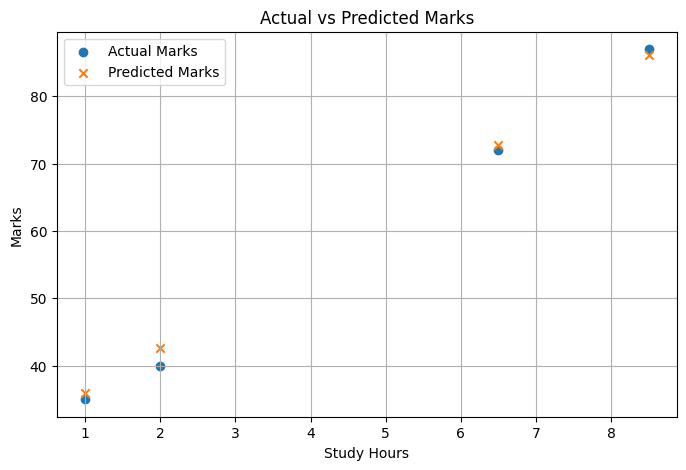

In [11]:
# Visualize actual and predicted marks

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test["Study_Hours"],
    y_test,
    label="Actual Marks"
)

plt.scatter(
    X_test["Study_Hours"],
    y_pred,
    label="Predicted Marks",
    marker="x"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Actual vs Predicted Marks")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Save the trained Machine Learning model

joblib.dump(model, "linear_regression_model.pkl")

print("Linear Regression model saved successfully!")

Linear Regression model saved successfully!


In [13]:
# Save prediction results to a CSV file

results.to_csv("prediction_results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [14]:
# Load the saved model
loaded_model = joblib.load("linear_regression_model.pkl")

# Make a prediction for a new input
new_data = pd.DataFrame({
    "Study_Hours": [6.0]
})

prediction = loaded_model.predict(new_data)

print("Study Hours:", 6.0)
print("Predicted Marks:", round(prediction[0], 2))

Study Hours: 6.0
Predicted Marks: 69.39


In [15]:
# Train the model again
model = LinearRegression()
model.fit(X_train, y_train)

# Save the trained model again
joblib.dump(model, "linear_regression_model.pkl")

print("Model trained and saved successfully!")

Model trained and saved successfully!


In [16]:
import joblib
import pandas as pd
import os

# Check the saved file
print("File exists:", os.path.exists("linear_regression_model.pkl"))
print("File size:", os.path.getsize("linear_regression_model.pkl"), "bytes")

# Load the model
loaded_model = joblib.load("linear_regression_model.pkl")

# Make a prediction
test_data = pd.DataFrame({"Study_Hours": [6.0]})
prediction = loaded_model.predict(test_data)

print("Model loaded successfully!")
print("Predicted marks:", round(prediction[0], 2))

File exists: True
File size: 833 bytes
Model loaded successfully!
Predicted marks: 69.39


In [17]:
import joblib

# Save the trained model again
joblib.dump(model, "linear_regression_model.pkl")

print("Model saved successfully!")

Model saved successfully!
